In [3]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device("cpu")

# Project paths
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "Images"
SPLIT_DIR = DATA_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Project directory:", PROJECT_DIR)
print("Setup completed!")

Device: cpu
Project directory: C:\B.tech\Project\Fetal_Ultrasound_Project
Setup completed!


In [4]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

df = pd.read_csv(DATA_DIR / "FETAL_PLANES_DB_data.csv", sep=";")
df.columns = df.columns.str.strip()

class_names = sorted(df["Plane"].unique())

class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Classes: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']
Number of classes: 6

Training images: 6217
Validation images: 912
Test images: 5271


Training class distribution:

Plane
Fetal abdomen       311
Fetal brain        1397
Fetal femur         453
Fetal thorax        922
Maternal cervix     825
Other              2309
Name: count, dtype: int64


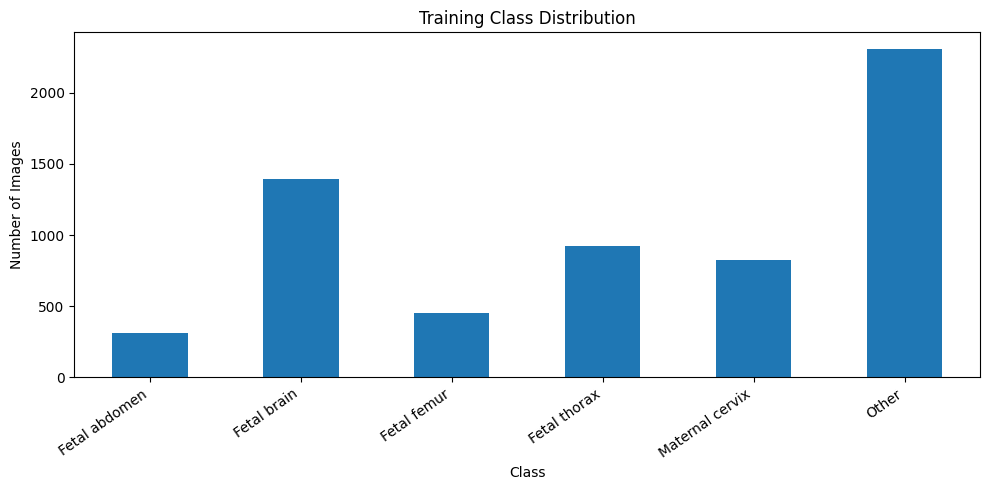

In [5]:
train_counts = (
    train_df["Plane"]
    .value_counts()
    .reindex(class_names)
)

print("Training class distribution:\n")
print(train_counts)

plt.figure(figsize=(10, 5))

train_counts.plot(kind="bar")

plt.title("Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [6]:
class_counts = torch.tensor(
    train_counts.values,
    dtype=torch.float32
)

class_weights = 1.0 / torch.sqrt(class_counts)

# Normalize weights
class_weights = class_weights / class_weights.mean()

class_weights = class_weights.to(DEVICE)

print("Class weights:\n")

for name, weight in zip(class_names, class_weights):
    print(f"{name}: {weight.item():.4f}")

Class weights:

Fetal abdomen: 1.5535
Fetal brain: 0.7330
Fetal femur: 1.2872
Fetal thorax: 0.9023
Maternal cervix: 0.9538
Other: 0.5701


In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Image transformations created successfully!")

Image transformations created successfully!


In [8]:
class FetalUltrasoundDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / f"{row['Image_name']}.png"

        image = Image.open(image_path).convert("RGB")

        label = class_to_idx[row["Plane"]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = FetalUltrasoundDataset(
    train_df,
    IMAGE_DIR,
    train_transform
)

val_dataset = FetalUltrasoundDataset(
    val_df,
    IMAGE_DIR,
    eval_transform
)

test_dataset = FetalUltrasoundDataset(
    test_df,
    IMAGE_DIR,
    eval_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 6217
Validation dataset: 912
Test dataset: 5271


In [9]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("DataLoaders created successfully!")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
DataLoaders created successfully!


In [10]:
weights = ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# Unfreeze final residual block
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace final classification layer
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(DEVICE)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Improved ResNet18 initialized!")
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)
print(
    "Trainable percentage:",
    round(100 * trainable_params / total_params, 2),
    "%"
)

Improved ResNet18 initialized!
Trainable parameters: 8396806
Total parameters: 11179590
Trainable percentage: 75.11 %


In [11]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    [
        {"params": model.layer4.parameters(), "lr": 1e-5},
        {"params": model.fc.parameters(), "lr": 1e-4}
    ],
    weight_decay=1e-4
)

EPOCHS = 3

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Epochs:", EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Epochs: 3


In [12]:
history = []

best_val_accuracy = 0.0
best_model_state = copy.deepcopy(model.state_dict())

MODEL_PATH = MODEL_DIR / "resnet18_improved_best.pth"

for epoch in range(EPOCHS):

    epoch_start = time.time()

    # -------------------------
    # Training
    # -------------------------

    model.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total

    train_accuracy = train_correct / train_total

    # -------------------------
    # Validation
    # -------------------------

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total

    val_accuracy = val_correct / val_total

    epoch_time = (time.time() - epoch_start) / 60

    # Save history
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "time_minutes": epoch_time
    })

    # Save best model using validation accuracy
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        best_model_state = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_model_state,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_val_accuracy": best_val_accuracy
        }, MODEL_PATH)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Time: {epoch_time:.2f} minutes")


print("\nImproved training completed!")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print("Best model saved at:", MODEL_PATH)


Epoch 1/3
Train Loss: 0.7998
Train Accuracy: 0.7726
Validation Loss: 0.3602
Validation Accuracy: 0.8936
Time: 9.76 minutes

Epoch 2/3
Train Loss: 0.3663
Train Accuracy: 0.8856
Validation Loss: 0.2460
Validation Accuracy: 0.9167
Time: 9.09 minutes

Epoch 3/3
Train Loss: 0.2759
Train Accuracy: 0.9122
Validation Loss: 0.2185
Validation Accuracy: 0.9254
Time: 9.54 minutes

Improved training completed!
Best validation accuracy: 0.9254
Best model saved at: C:\B.tech\Project\Fetal_Ultrasound_Project\models\resnet18_improved_best.pth


Training history:


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,time_minutes
0,1,0.799791,0.360150,0.772559,0.893640,9.757584
1,2,0.366294,0.246005,0.885636,0.916667,9.086979
2,3,0.275892,0.218454,0.912176,0.925439,9.544159


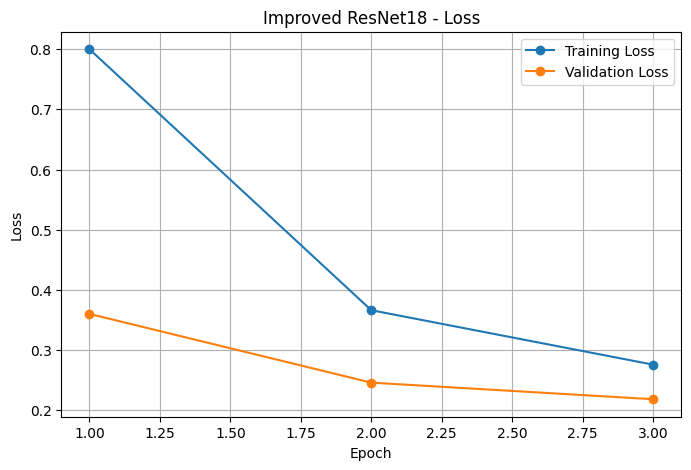

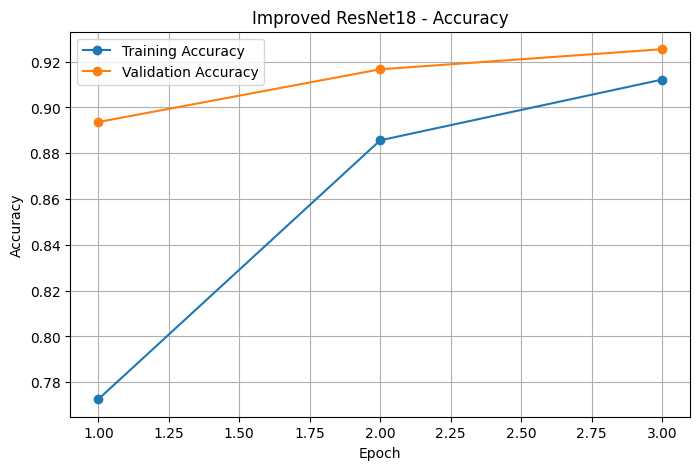

Training history and plots saved!


In [13]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULT_DIR / "improved_training_history.csv",
    index=False
)

print("Training history:")
display(history_df)

# Plot loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved ResNet18 - Loss")

plt.legend()
plt.grid(True)
plt.savefig(RESULT_DIR / "improved_loss_curve.png", dpi=300)
plt.show()


# Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved ResNet18 - Accuracy")

plt.legend()
plt.grid(True)
plt.savefig(RESULT_DIR / "improved_accuracy_curve.png", dpi=300)
plt.show()

print("Training history and plots saved!")

In [14]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())


all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Improved Model Test Accuracy: {test_accuracy * 100:.2f}%")
print("Total test predictions:", len(all_predictions))

Improved Model Test Accuracy: 89.34%
Total test predictions: 5271


In [15]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    RESULT_DIR / "improved_classification_report.csv"
)

print("Classification report saved!")

                 precision    recall  f1-score   support

  Fetal abdomen     0.8223    0.8659    0.8435       358
    Fetal brain     0.9850    0.9823    0.9837      1472
    Fetal femur     0.7372    0.9046    0.8123       524
   Fetal thorax     0.7579    0.9439    0.8408       660
Maternal cervix     0.9938    0.9984    0.9961       645
          Other     0.9231    0.7519    0.8287      1612

       accuracy                         0.8934      5271
      macro avg     0.8699    0.9078    0.8842      5271
   weighted avg     0.9030    0.8934    0.8934      5271

Classification report saved!


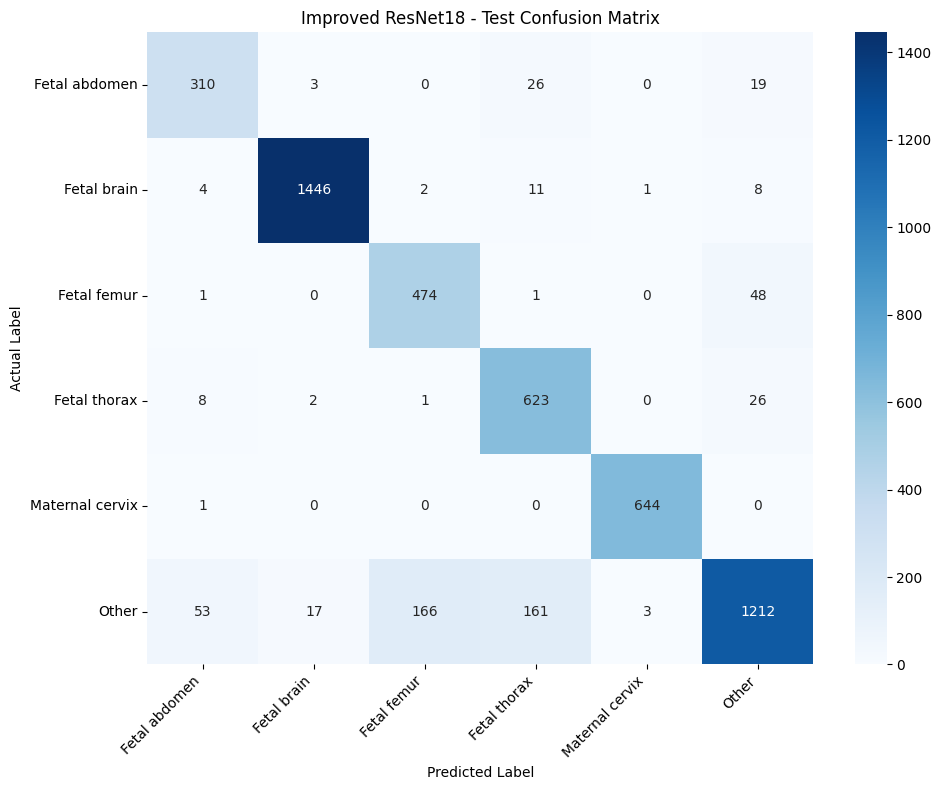

In [16]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Improved ResNet18 - Test Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "improved_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
improved_predictions_df = pd.DataFrame({
    "Actual": [class_names[i] for i in all_labels],
    "Predicted": [class_names[i] for i in all_predictions]
})

improved_predictions_df.to_csv(
    RESULT_DIR / "improved_test_predictions.csv",
    index=False
)

print("Improved model predictions saved!")
print("Results directory:", RESULT_DIR)

Improved model predictions saved!
Results directory: C:\B.tech\Project\Fetal_Ultrasound_Project\results


In [18]:
baseline_predictions = pd.read_csv(
    RESULT_DIR / "baseline_test_predictions.csv"
)

baseline_accuracy = accuracy_score(
    baseline_predictions["Actual"],
    baseline_predictions["Predicted"]
)

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline ResNet18",
        "Improved ResNet18"
    ],
    "Test Accuracy": [
        baseline_accuracy,
        test_accuracy
    ]
})

comparison_df["Test Accuracy (%)"] = (
    comparison_df["Test Accuracy"] * 100
)

display(comparison_df)

improvement = (
    test_accuracy - baseline_accuracy
) * 100

print(f"Accuracy difference: {improvement:+.2f} percentage points")

,Model,Test Accuracy,Test Accuracy (%)
0,Baseline ResNet18,0.937204,93.720357
1,Improved ResNet18,0.893379,89.337887


Accuracy difference: -4.38 percentage points
